# Modelado y comparación de modelos

## Entrega P2

Este cuaderno entrena y compara los clasificadores sobre la tabla de descriptores construida en el cuaderno 03. Todo el diseño experimental sigue las dos condiciones que fijó P1: ninguna partición puede repartir datos de un mismo sujeto entre entrenamiento y prueba, y la búsqueda de hiperparámetros ocurre dentro del bucle de validación.

In [1]:
import subprocess
import sys
from pathlib import Path

REPOSITORIO = "https://github.com/jeraldinedione/proyecto-machine-learning.git"


def raiz_del_proyecto(inicio: Path) -> Path:
    for carpeta in [inicio, *inicio.parents]:
        if (carpeta / "src" / "gait").is_dir():
            return carpeta
    raise FileNotFoundError("No se encontró la raíz del proyecto")


if "google.colab" in sys.modules:
    if not Path("marcha").exists():
        subprocess.run(["git", "clone", "--quiet", REPOSITORIO, "marcha"], check=True)
    RAIZ = Path("marcha").resolve()
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "--quiet", "-r", str(RAIZ / "requirements.txt")],
        check=True,
    )
else:
    RAIZ = raiz_del_proyecto(Path.cwd())

sys.path.insert(0, str(RAIZ / "src"))
print(RAIZ)

/Users/nllerenas/Chiwawa/proyecto-machine-learning


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import RepeatedStratifiedKFold, permutation_test_score

from gait import cohort, config, download, evaluation, gaitndd, models, plots

download.fetch(config.GAITNDD)
plots.use_paper_style()
config.TABLES_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

In [3]:
sujetos = gaitndd.read_subject_table()
zancadas = cohort.clean_strides(gaitndd.read_all_strides())
datos = cohort.subject_dataset(zancadas, sujetos)
print(datos.group.value_counts().reindex(config.GROUP_ORDER).rename(index=config.GROUP_LABELS).to_string())

group
Control       16
Parkinson     15
Huntington    19
ELA           13


---

## 1. Diseño experimental

**Validación externa (evaluación).** Validación cruzada estratificada de 5 particiones sobre los 63 sujetos, repetida 10 veces con semillas distintas: 50 pares entrenamiento/prueba, con unos 50 sujetos para entrenar y 12 o 13 para probar en cada uno. Cada repetición produce exactamente una predicción fuera de muestra por sujeto. Las métricas se calculan por repetición sobre los 63 sujetos y se reporta la media y la desviación estándar entre las 10 repeticiones. Con 12 sujetos de prueba, una métrica calculada partición por partición sería demasiado ruidosa.

**Validación interna (ajuste).** Dentro de cada partición de entrenamiento, `GridSearchCV` con 5 particiones estratificadas y agrupadas por sujeto elige los hiperparámetros por exactitud balanceada, reentrena con todo el entrenamiento y recién entonces se predice la partición de prueba. Los sujetos de prueba no participan en ninguna decisión.

**Métricas.**
- Exactitud balanceada (principal): promedio de la sensibilidad de las cuatro clases. No depende del tamaño de cada grupo; el azar es 0.25.
- F1 macro: penaliza también las falsas alarmas de cada clase.
- AUC macro uno contra el resto: evalúa el orden de las probabilidades, sin depender de un umbral.
- Sensibilidad por clase, para ver dónde falla cada modelo.

**Comparación entre modelos.** Todos los modelos usan exactamente las mismas 50 particiones, así que las diferencias son pareadas. Para decidir si una diferencia es mayor que el ruido se usa la prueba t corregida para remuestreo de Nadeau y Bengio, que infla la varianza para compensar que los conjuntos de entrenamiento de las distintas particiones se solapan.

In [4]:
particiones = evaluation.record_splits(datos, n_splits=5, n_repeats=10)
tamanos = pd.Series([len(prueba) for _, prueba in particiones])
print(f"{len(particiones)} particiones, sujetos de prueba por partición: {tamanos.min()} a {tamanos.max()}")

50 particiones, sujetos de prueba por partición: 12 a 13


---

## 2. Modelos

**Referencias.**
- *Clase mayoritaria*: predice siempre Huntington, el grupo más grande. Fija el piso de la exactitud balanceada en 0.25.
- *LR sobre CV y DFA*: regresión logística sin ajuste de hiperparámetros con los dos marcadores clásicos de Hausdorff (variabilidad y correlaciones de largo alcance). Responde a la pregunta de cuánto se gana respecto de lo que ya proponía la literatura con dos números.

**Modelos.** Todos usan los 12 descriptores de marcha y pesos de clase balanceados.
- *Regresión logística multinomial* con penalización elastic net (`saga`). Es el modelo natural para 63 observaciones: pocos parámetros, la penalización controla la redundancia entre descriptores y los coeficientes se interpretan.
- *SVM con kernel RBF*, para permitir fronteras no lineales sin muchos parámetros. Sus probabilidades se calibran con el método sigmoide en 3 particiones internas, porque `SVC(probability=True)` está obsoleto desde scikit-learn 1.9.
- *Bosque aleatorio*, que capta interacciones y no necesita escalamiento.
- *Gradient boosting*, incluido para ver si un ensamble secuencial aprovecha algo con tan pocos datos.

La tabla muestra el espacio de búsqueda de cada uno.

In [5]:
suite = models.comparison_suite()
espacio = pd.DataFrame([
    {
        "modelo": spec.label,
        "variables": len(spec.features),
        "hiperparámetro": clave.split("__")[-1],
        "valores": ", ".join(str(v) for v in valores),
    }
    for spec in suite
    for clave, valores in (spec.grid or {"(sin ajuste)": ["-"]}).items()
])
espacio.to_csv(config.TABLES_DIR / "espacio_hiperparametros.csv", index=False)
espacio.set_index(["modelo", "variables"])

hiperparámetro                               valores
modelo              variables                                                        
Clase mayoritaria   12             (sin ajuste)                                     -
LR sobre CV y DFA   2              (sin ajuste)                                     -
Regresión logística 12                        C  0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0
                    12                 l1_ratio                         0.0, 0.5, 1.0
SVM (RBF)           12                        C             0.3, 1.0, 3.0, 10.0, 30.0
                    12                    gamma                scale, 0.01, 0.03, 0.1
Bosque aleatorio    12                max_depth                               None, 4
                    12         min_samples_leaf                               1, 3, 5
                    12             max_features                             sqrt, 0.5
Gradient boosting   12             n_estimators                              100, 300
                    12            learning_rate                             0.03, 0.1
                    12                max_depth                               1, 2, 3

---

## 3. Validación cruzada anidada

In [6]:
%%time
resultados = {
    spec.name: evaluation.nested_cv(spec, datos, particiones, importances=spec.name in {"logistica", "bosque"})
    for spec in suite
}

CPU times: user 1min 49s, sys: 2.07 s, total: 1min 51s
Wall time: 3min 18s


In [7]:
resumen = evaluation.summarize(list(resultados.values()), config.GROUP_ORDER)
resumen.to_csv(config.TABLES_DIR / "comparacion_modelos.csv")


def media_de(tabla, columna):
    return tabla[f"{columna}_mean"].map("{:.3f}".format) + " ± " + tabla[f"{columna}_sd"].map("{:.3f}".format)


pd.DataFrame({
    "exactitud bal.": media_de(resumen, "balanced_accuracy"),
    "F1 macro": media_de(resumen, "macro_f1"),
    "AUC": media_de(resumen, "auc"),
    **{f"sens. {config.GROUP_SHORT[g]}": resumen[f"recall_{g}_mean"].round(2) for g in config.GROUP_ORDER},
})

,exactitud bal.,F1 macro,AUC,sens. Ctrl,sens. EP,sens. EH,sens. ELA
modelo,,,,,,,
Clase mayoritaria,0.250 ± 0.000,0.116 ± 0.000,0.500 ± 0.000,0.000,0.000,1.000,0.000
LR sobre CV y DFA,0.538 ± 0.034,0.519 ± 0.036,0.735 ± 0.017,0.880,0.250,0.670,0.350
Regresión logística,0.591 ± 0.041,0.583 ± 0.045,0.812 ± 0.026,0.820,0.370,0.660,0.520
SVM (RBF),0.537 ± 0.026,0.508 ± 0.025,0.783 ± 0.022,0.860,0.170,0.650,0.480
Bosque aleatorio,0.605 ± 0.016,0.595 ± 0.018,0.829 ± 0.018,0.880,0.370,0.660,0.520
Gradient boosting,0.566 ± 0.049,0.560 ± 0.053,0.763 ± 0.026,0.790,0.390,0.660,0.420


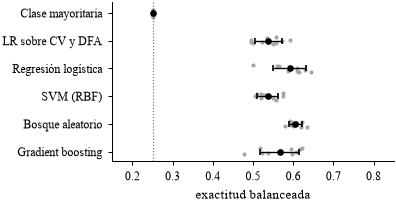

In [8]:
metricas = {nombre: evaluation.repeat_metrics(r, config.GROUP_ORDER) for nombre, r in resultados.items()}
rng = np.random.default_rng(config.RANDOM_STATE)

fig, ax = plt.subplots(figsize=(plots.COLUMN_WIDTH, 1.9))
for fila, (nombre, tabla) in enumerate(metricas.items()):
    valores = tabla.balanced_accuracy.to_numpy()
    ax.scatter(valores, fila + rng.uniform(-0.15, 0.15, len(valores)), s=6, color="0.65", lw=0)
    ax.errorbar(valores.mean(), fila, xerr=valores.std(ddof=1), fmt="o", color="black", ms=3, capsize=2, lw=0.8)
ax.axvline(0.25, color="0.4", ls=":", lw=0.7)
ax.set_yticks(range(len(metricas)), [resultados[n].spec.label for n in metricas])
ax.invert_yaxis()
ax.set_xlim(0.15, 0.85)
ax.set_xlabel("exactitud balanceada")
fig.tight_layout()
plots.save(fig, "comparacion_modelos")

Los cuatro modelos superan con claridad a la clase mayoritaria y quedan entre 0.54 y 0.61. El bosque aleatorio tiene la media más alta (0.605) y también la menor desviación entre repeticiones (0.016): su resultado depende menos de cómo caen los sujetos en las particiones. La regresión logística queda cerca (0.591) pero varía más. El SVM no supera a la referencia de dos variables y reconoce muy pocos casos de Parkinson (0.17).

En todos los modelos Parkinson es la clase más difícil (sensibilidad entre 0.17 y 0.39) y control la más fácil (0.79 a 0.88).

Cada punto gris es una repetición completa de la validación cruzada (63 predicciones fuera de muestra); el punto negro es la media y la barra, una desviación estándar. La línea punteada es el azar.

---

## 4. ¿Las diferencias son reales?

La prueba se aplica a las exactitudes balanceadas de las 50 particiones. La corrección usa la fracción de prueba (13/50).

In [9]:
puntajes = {nombre: evaluation.fold_scores(r) for nombre, r in resultados.items()}
n_prueba = len(datos) / 5
n_entrenamiento = len(datos) - n_prueba
candidatos = ["logistica", "svm", "bosque", "boosting"]
mejor = resumen.loc[[resultados[n].spec.label for n in candidatos], "balanced_accuracy_mean"].idxmax()
mejor_nombre = next(n for n in candidatos if resultados[n].spec.label == mejor)

filas = []
for nombre in candidatos:
    for referencia in ["clasico", mejor_nombre]:
        if nombre == referencia:
            continue
        t, p = evaluation.corrected_ttest(puntajes[nombre], puntajes[referencia], n_entrenamiento, n_prueba)
        filas.append({
            "modelo": resultados[nombre].spec.label,
            "contra": resultados[referencia].spec.label,
            "diferencia": (puntajes[nombre] - puntajes[referencia]).mean(),
            "t corregido": t,
            "p": p,
        })
contrastes = pd.DataFrame(filas)
contrastes.to_csv(config.TABLES_DIR / "contrastes_modelos.csv", index=False)
print("mejor modelo por exactitud balanceada media:", mejor)
contrastes

mejor modelo por exactitud balanceada media: Bosque aleatorio


,modelo,contra,diferencia,t corregido,p
0,Regresión logística,LR sobre CV y DFA,0.054,0.696,0.490
1,Regresión logística,Bosque aleatorio,-0.015,-0.245,0.808
2,SVM (RBF),LR sobre CV y DFA,-0.002,-0.021,0.983
3,SVM (RBF),Bosque aleatorio,-0.071,-1.205,0.234
4,Bosque aleatorio,LR sobre CV y DFA,0.069,0.892,0.377
5,Gradient boosting,LR sobre CV y DFA,0.026,0.272,0.787
6,Gradient boosting,Bosque aleatorio,-0.043,-0.674,0.504


Ninguna diferencia es significativa, ni siquiera la del bosque contra la referencia de dos variables (p = 0.38). Con 12 o 13 sujetos de prueba por partición, un solo sujeto mal clasificado en una clase de tres sujetos mueve la exactitud balanceada de esa partición en 0.08; la prueba corregida tiene en cuenta esa variabilidad. Que un modelo tenga mayor media no alcanza para decir que es mejor. Lo que sí se puede afirmar es que todos superan al azar (sección 7).

---

## 5. Hiperparámetros elegidos

Que la validación interna elija siempre la misma combinación es una señal de estabilidad; que cambie de partición en partición indica que con ~50 sujetos varias combinaciones rinden casi igual.

In [10]:
elegidos = []
for nombre in candidatos:
    combinaciones = resultados[nombre].params.drop(columns=["repeat", "fold"]).astype(object).fillna("None").astype(str)
    combinaciones.columns = [c.split("__")[-1] for c in combinaciones.columns]
    conteo = combinaciones.apply(lambda fila: ", ".join(f"{k}={v}" for k, v in fila.items()), axis=1).value_counts()
    elegidos.append({
        "modelo": resultados[nombre].spec.label,
        "combinación más frecuente": conteo.index[0],
        "veces elegida (de 50)": conteo.iloc[0],
        "combinaciones distintas": len(conteo),
    })
elegidos = pd.DataFrame(elegidos).set_index("modelo")
elegidos.to_csv(config.TABLES_DIR / "hiperparametros_elegidos.csv")
elegidos

,combinación más frecuente,veces elegida (de 50),combinaciones distintas
modelo,,,
Regresión logística,"C=0.03, l1_ratio=0.0",5,14
SVM (RBF),"C=10.0, gamma=0.03",8,16
Bosque aleatorio,"max_depth=None, max_features=sqrt, min_samples...",20,7
Gradient boosting,"learning_rate=0.1, max_depth=3, n_estimators=100",8,12


In [11]:
penalizacion = resultados["logistica"].params.rename(columns=lambda c: c.split("__")[-1])
pd.crosstab(penalizacion.C, penalizacion.l1_ratio, margins=True, margins_name="total")

l1_ratio,0.000,0.500,1.000,total
C,,,,
0.010,2,0,0,2
0.030,5,0,0,5
0.100,5,2,0,7
0.300,5,4,1,10
1.000,5,5,5,15
3.000,4,3,2,9
10.000,2,0,0,2
total,28,14,8,50


La logística eligió 14 combinaciones distintas en 50 particiones y la más frecuente apenas 5 veces, casi siempre con C entre 0.03 y 3. La exactitud interna es casi plana en esa región: muchas combinaciones rinden parecido y la elección depende de qué sujetos tocaron en la partición. El bosque es más estable: la misma combinación (árboles sin límite de profundidad, hojas de un sujeto, √p variables por división) aparece en 20 de las 50 particiones.

---

## 6. Segundo enfoque: entrenar con ventanas, decidir por sujeto

En P1 las ventanas de 30 zancadas se usaron para mostrar la fuga. Aquí se usan bien: las particiones son las mismas 50 de arriba (definidas sobre sujetos), la validación interna agrupa las ventanas por sujeto, y para cada sujeto de prueba se promedian las probabilidades de sus ventanas antes de decidir. El modelo ve unas ocho veces más filas de entrenamiento, pero cada sujeto sigue contando una sola vez en la evaluación.

Como en las ventanas no se usa la entropía muestral (cuaderno 03), la comparación justa es contra los mismos modelos entrenados por sujeto con esos 11 descriptores.

In [12]:
%%time
ventanas = cohort.window_dataset(zancadas, sujetos, window_strides=30)
variables_ventana = [f for f in config.GAIT_FEATURES if f != "sample_entropy"]

enfoques = {
    "logistica_sujeto": models.logistic(variables_ventana).labelled("Logística, por sujeto"),
    "logistica_ventana": models.logistic(variables_ventana).labelled("Logística, por ventanas"),
    "bosque_sujeto": models.random_forest(variables_ventana).labelled("Bosque, por sujeto"),
    "bosque_ventana": models.random_forest(variables_ventana).labelled("Bosque, por ventanas"),
}
por_enfoque = {
    nombre: evaluation.nested_cv(spec, ventanas if nombre.endswith("ventana") else datos, particiones)
    for nombre, spec in enfoques.items()
}

CPU times: user 31.2 s, sys: 1.06 s, total: 32.3 s
Wall time: 2min 19s


In [13]:
resumen_ventanas = evaluation.summarize(list(por_enfoque.values()), config.GROUP_ORDER)
resumen_ventanas.to_csv(config.TABLES_DIR / "enfoque_ventanas.csv")

filas = []
for modelo in ["logistica", "bosque"]:
    a, b = por_enfoque[f"{modelo}_ventana"], por_enfoque[f"{modelo}_sujeto"]
    t, p = evaluation.corrected_ttest(evaluation.fold_scores(a), evaluation.fold_scores(b), n_entrenamiento, n_prueba)
    filas.append({"modelo": modelo, "ventanas - sujeto": (evaluation.fold_scores(a) - evaluation.fold_scores(b)).mean(), "p": p})

display(pd.DataFrame({
    "exactitud bal.": media_de(resumen_ventanas, "balanced_accuracy"),
    "F1 macro": media_de(resumen_ventanas, "macro_f1"),
    "AUC": media_de(resumen_ventanas, "auc"),
}))
pd.DataFrame(filas)

,exactitud bal.,F1 macro,AUC
modelo,,,
"Logística, por sujeto",0.588 ± 0.052,0.572 ± 0.056,0.810 ± 0.036
"Logística, por ventanas",0.641 ± 0.030,0.625 ± 0.031,0.824 ± 0.013
"Bosque, por sujeto",0.613 ± 0.029,0.603 ± 0.029,0.823 ± 0.020
"Bosque, por ventanas",0.647 ± 0.028,0.631 ± 0.029,0.862 ± 0.016


,modelo,ventanas - sujeto,p
0,logistica,0.050,0.492
1,bosque,0.036,0.561


Entrenar con ventanas sube la media en los dos modelos (+0.05 la logística, +0.04 el bosque), con la evaluación siempre por sujeto, aunque la diferencia no es significativa (p ≈ 0.5). A diferencia del experimento de P1, aquí la mejora no puede venir de fuga: ningún sujeto de prueba tiene ventanas en el entrenamiento. Lo que cambia es que el modelo ve cómo varía cada sujeto de una ventana a otra, lo que funciona como un aumento de datos.

Esto responde la segunda parte de la PI2: las ventanas no son el problema; el problema era evaluarlas como si fueran independientes.

---

## 7. ¿El mejor modelo supera al azar?

La desviación entre repeticiones no dice si el resultado podría aparecer con etiquetas sin relación con la marcha. La prueba de permutación responde eso: se barajan las etiquetas 1000 veces y se repite la validación cruzada con cada barajado. Para que sea computable se fijan los hiperparámetros en la combinación elegida con más frecuencia, sin búsqueda interna; eso hace el puntaje observado algo optimista, pero también el de las permutaciones, así que la comparación sigue siendo válida.

In [14]:
%%time
fijos = evaluation.most_frequent_params(resultados[mejor_nombre])
especificacion = next(s for s in suite if s.name == mejor_nombre).with_params(**fijos)
observado, nulos, p_valor = permutation_test_score(
    especificacion.estimator,
    datos[especificacion.features],
    datos.group,
    scoring="balanced_accuracy",
    cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=config.RANDOM_STATE),
    n_permutations=1000,
    n_jobs=-1,
    random_state=config.RANDOM_STATE,
)
print(f"hiperparámetros fijos: {fijos}")
print(f"exactitud balanceada observada: {observado:.3f}")
print(f"permutaciones: media {nulos.mean():.3f}, percentil 99 {np.percentile(nulos, 99):.3f}, máximo {nulos.max():.3f}")
print(f"p = {p_valor:.4f}")

hiperparámetros fijos: {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': np.int64(1)}
exactitud balanceada observada: 0.633
permutaciones: media 0.248, percentil 99 0.396, máximo 0.463
p = 0.0010
CPU times: user 2.5 s, sys: 234 ms, total: 2.73 s
Wall time: 2min 30s


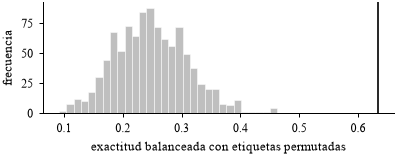

In [15]:
fig, ax = plt.subplots(figsize=(plots.COLUMN_WIDTH, 1.5))
ax.hist(nulos, bins=30, color="0.75", edgecolor="white", lw=0.3)
ax.axvline(observado, color="black", lw=1)
ax.set_xlabel("exactitud balanceada con etiquetas permutadas")
ax.set_ylabel("frecuencia")
fig.tight_layout()
plots.save(fig, "prueba_permutacion")

Ninguna de las 1000 permutaciones alcanzó el puntaje observado (0.633 frente a un máximo de 0.463), así que p = 0.001, el mínimo que permite este número de permutaciones.

---

## 8. Los 19 descriptores de P1

Una versión preliminar del modelado usó los 19 descriptores que devuelve `features.subject_features` (los de P1) y una sola validación cruzada de 5 particiones. Con ese esquema el bosque aleatorio llegaba a una exactitud balanceada de 0.725 ± 0.085. Ese conjunto incluye tres variables que el cuaderno 03 dejó fuera porque dependen del largo del registro y del filtrado: el número de zancadas, la duración observada y la cadencia.

Se repite aquí con el protocolo anidado 5 × 10 para separar dos efectos: cuánto de la diferencia se debe a usar una sola partición y cuánto aportan esas tres variables. La columna "DE entre particiones" es la desviación entre las 5 particiones de una misma repetición (lo que se reporta con una sola validación cruzada), promediada sobre las 10 repeticiones.

In [16]:
%%time
p1_sin_duracion = [f for f in config.P1_FEATURES if f not in config.DURATION_FEATURES]
preliminar = {
    "bosque_19": evaluation.nested_cv(
        models.random_forest(config.P1_FEATURES).labelled("Bosque, 19 de P1"), datos, particiones, importances=True
    ),
    "bosque_16": evaluation.nested_cv(
        models.random_forest(p1_sin_duracion).labelled("Bosque, 16 sin duración"), datos, particiones
    ),
    "logistica_19": evaluation.nested_cv(
        models.logistic(config.P1_FEATURES).labelled("Logística, 19 de P1"), datos, particiones
    ),
    "logistica_16": evaluation.nested_cv(
        models.logistic(p1_sin_duracion).labelled("Logística, 16 sin duración"), datos, particiones
    ),
    "bosque_12": resultados["bosque"],
    "logistica_12": resultados["logistica"],
}

CPU times: user 2min 23s, sys: 2.27 s, total: 2min 25s
Wall time: 3min 39s


In [17]:
filas = []
for resultado in preliminar.values():
    metricas = evaluation.repeat_metrics(resultado)
    pliegues = evaluation.fold_scores(resultado)
    filas.append({
        "modelo": resultado.spec.label,
        "variables": len(resultado.spec.features),
        "exactitud bal.": metricas.balanced_accuracy.mean(),
        "DE entre repeticiones": metricas.balanced_accuracy.std(ddof=1),
        "peor repetición": metricas.balanced_accuracy.min(),
        "mejor repetición": metricas.balanced_accuracy.max(),
        "DE entre particiones": pliegues.groupby(level="repeat").std().mean(),
        "mejor partición": pliegues.max(),
    })
comparacion_p1 = pd.DataFrame(filas).set_index("modelo")
comparacion_p1.to_csv(config.TABLES_DIR / "conjunto_p1.csv")
comparacion_p1

,variables,exactitud bal.,DE entre repeticiones,peor repetición,mejor repetición,DE entre particiones,mejor partición
modelo,,,,,,,
"Bosque, 19 de P1",19,0.628,0.030,0.576,0.667,0.143,0.938
"Bosque, 16 sin duración",16,0.603,0.026,0.559,0.631,0.130,0.854
"Logística, 19 de P1",19,0.668,0.038,0.616,0.729,0.149,0.938
"Logística, 16 sin duración",16,0.618,0.020,0.585,0.641,0.140,0.854
Bosque aleatorio,12,0.605,0.016,0.580,0.635,0.123,0.854
Regresión logística,12,0.591,0.041,0.501,0.645,0.120,0.854


In [18]:
importancia_p1 = preliminar["bosque_19"].importances.agg(["mean", "std"]).T.sort_values("mean", ascending=False)
importancia_p1.columns = ["caída media", "DE entre particiones"]
importancia_p1.head(8)

,caída media,DE entre particiones
dfa_alpha,0.036,0.052
stride_iqr,0.033,0.054
n_strides,0.022,0.071
autocorr_lag1,0.012,0.049
swing_pct_cv,0.012,0.054
double_support_pct_mean,0.012,0.038
swing_pct_iqr,0.009,0.053
observed_span_s,0.007,0.031


Tres observaciones.

1. Una sola validación cruzada de 5 particiones tiene una desviación entre particiones de 0.12 a 0.15, con particiones que llegan a 0.94. El 0.725 ± 0.085 de la versión preliminar es un resultado posible de una sola corrida, pero el mismo bosque con los 19 descriptores promedia 0.628 sobre 10 repeticiones.
2. Las variables de duración sí aportan dentro de `gaitndd`: quitarlas baja el bosque de 0.628 a 0.603 y la logística de 0.668 a 0.618. El número de zancadas es el tercer descriptor más importante del bosque.
3. Los 12 descriptores de este trabajo no mejoran a los 16 de P1 sin duración (0.605 y 0.591 contra 0.603 y 0.618). Las dos variables nuevas no agregaron información que no estuviera ya en las medidas de variabilidad.

Entonces, ¿por qué no usar los 19? Porque lo que aportan las variables de duración no se sostiene fuera de esta cohorte. El número de zancadas válidas depende de la velocidad, del filtrado y de cuánto dura el registro. La sección 6 del cuaderno 06 muestra que, con ellas, la regresión logística entrenada en `gaitndd` clasifica a casi todos los sujetos de `gaitpdb` como controles.

In [19]:
for nombre, resultado in resultados.items():
    resultado.predictions.to_csv(config.TABLES_DIR / f"predicciones_{nombre}.csv", index=False)